# 3 · Embeddings + pgvector + Retrieval-Augmented Generation | 50 minutes
Build a complete RAG loop: **documents → embeddings → vector store → similarity search → OpenAI answer grounded in sources**.

The instructor already embedded 18 fictional KB articles into Supabase (`shared.knowledge_articles`). You will create **one new article**, store its OpenAI embedding in your team table, and ask grounded questions. **The Kaggle `Resolution` text is not used as the knowledge base**—it is synthetic/noisy and not a trustworthy support policy.

**OpenAI credentials:** use your own *budgeted* API key or instructor-provided authenticated proxy. Never use/distribute the instructor's master API key. Embeddings cost API usage.

## Why RAG?
An LLM only knows what was in its training data. It has never seen *your* company's support policies, and when it does not know, it may still produce a confident-sounding answer. **RAG (Retrieval-Augmented Generation)** fixes this by looking up the relevant pieces of your own knowledge first and handing them to the LLM together with the question, so the answer is **grounded in your sources**.

![RAG overview: documents and the query are encoded by an embedding model, similar documents are fetched from the vector database, and the LLM answers from them](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/rag.gif)

## The map: 8 steps in two phases
```
 PART 0 · CONCEPTS (no database needed): what is a vector? what is a vector database?

 PHASE A · INDEXING (prepare the knowledge once)
   1 Chunk  ──►  2 Embed  ──►  3 Store in vector DB

 PHASE B · QUERY (every time a user asks)
   4 Question ─► 5 Embed question ─► 6 Retrieve top-k ─► 7 Re-rank (optional) ─► 8 Generate answer
```

![Architecture of a typical RAG system: knowledge base, chunking, embedding model, vector database, optional re-ranker, prompt template and LLM](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-2.png)
*Diagrams in this notebook: Daily Dose of Data Science, "Foundations of RAG systems".* (The original uses Llama and Qdrant; this lab uses OpenAI and pgvector, the flow is the same.)
Each section below is one step. Every step tells you **what it does**, **why it exists**, and **what you should see** when you run it. Only four cells need your code: `TODO 0` (Part 0), `TODO 1`, `TODO 2`, `TODO 3`.

## Setup: connect to the database and OpenAI
Two things power this lab:
- **Supabase Postgres + pgvector** = the *vector database* (the memory of our RAG app).
- **OpenAI** = the *embedding model* (text → numbers) and the *LLM* (writes the final answer).

The next two cells connect to both. They are provided; just run them.

In [1]:
%pip install -q python-dotenv "psycopg[binary]>=3.2,<4" "pandas>=2.2,<3" "plotly>=5,<7" "openai>=1.55,<3"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, getpass
from dotenv import load_dotenv
load_dotenv()
from contextlib import closing
import psycopg
from psycopg import sql
import pandas as pd

# Reenter these in EACH notebook. Use the team credential supplied privately by your instructor.
PROJECT_REF = os.getenv("LAB_PROJECT_REF") or input("Supabase project ref: ").strip()
POOLER_HOST = os.getenv("LAB_POOLER_HOST") or input("Transaction pooler host (not full URL): ").strip()
TEAM_NUMBER = int(os.getenv("LAB_TEAM_NUMBER") or input("Team number (e.g. 1): ").strip())
TEAM_SCHEMA = f"team_{TEAM_NUMBER:02d}"
DB_PASSWORD = os.getenv("LAB_DB_PASSWORD") or getpass.getpass("Team database password: ")
DB_USER = f"lab_team_{TEAM_NUMBER:02d}.{PROJECT_REF}"

def connect():
    # Supabase Free transaction pooler; psycopg prepared statements disabled.
    return psycopg.connect(host=POOLER_HOST, port=6543, dbname="postgres",
                           user=DB_USER, password=DB_PASSWORD, sslmode="require",
                           connect_timeout=12, prepare_threshold=None)

def fetch_df(query, params=None):
    with closing(connect()) as conn:
        with conn.cursor() as cur:
            cur.execute(query, params)
            if cur.description is None: return pd.DataFrame()
            return pd.DataFrame(cur.fetchall(), columns=[x.name for x in cur.description])

def run_sql(query, params=None):
    with closing(connect()) as conn:
        with conn.transaction():
            with conn.cursor() as cur:
                cur.execute(query, params)

print("Connected to:", TEAM_SCHEMA)
print(fetch_df("SELECT current_user AS user_name, current_database() AS db_name"))

Connected to: team_01
     user_name   db_name
0  lab_team_01  postgres


In [3]:
import os, getpass
from openai import OpenAI
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY") or getpass.getpass("Your budgeted OpenAI API key (never instructor master key): ")
client = OpenAI(api_key=OPENAI_API_KEY)
EMBED_MODEL = "text-embedding-3-small"      # 1536 dimensions by default
CHAT_MODEL = "gpt-4.1-mini"

def embed(text):
    return client.embeddings.create(model=EMBED_MODEL, input=text).data[0].embedding

def vector_literal(vector):
    assert len(vector) == 1536, "Embedding dimension must match vector(1536)"
    return "[" + ",".join(str(float(x)) for x in vector) + "]"

---
# Part 0 · Vectors and vector databases (the ideas behind Steps 2-6)
Before we build the pipeline, let's understand its two core ingredients with a **small toy example you can see and play with**. No database or API calls in this part: only `numpy` and a plot.

## 0.1 What is a vector?
A **vector** is just an ordered list of numbers, for example `[0.2, -1.7, 2.3]`. You can read it as a **point (or an arrow) in space**:
- 2 numbers = a point on a map,
- 3 numbers = a point in a room,
- 1,536 numbers (what OpenAI's embedding model returns) = a point in a space we cannot picture, but the maths works exactly the same.

An **embedding model** turns unstructured data (text, images, audio, video) into such a vector. It is trained so that **similar meaning ends up at nearby points**.

![Unstructured data (images, documents, video, audio) is converted into rows of numbers, the embeddings](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-160.png)

For example, after training, the embeddings of fruits cluster together, cities form another cluster, birds another, and so on. The model was never told these categories: it learned them from how words are used.

![Embeddings of fruits, cities and birds form separate clusters in the embedding space](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-161.png)

Real embeddings have too many dimensions to draw, so below we use a **toy map with 2 dimensions**. We placed these 9 support topics **by hand** (the numbers are invented, a real model would compute them), grouped into 3 topics. The axes have no human meaning, in real models they don't either.

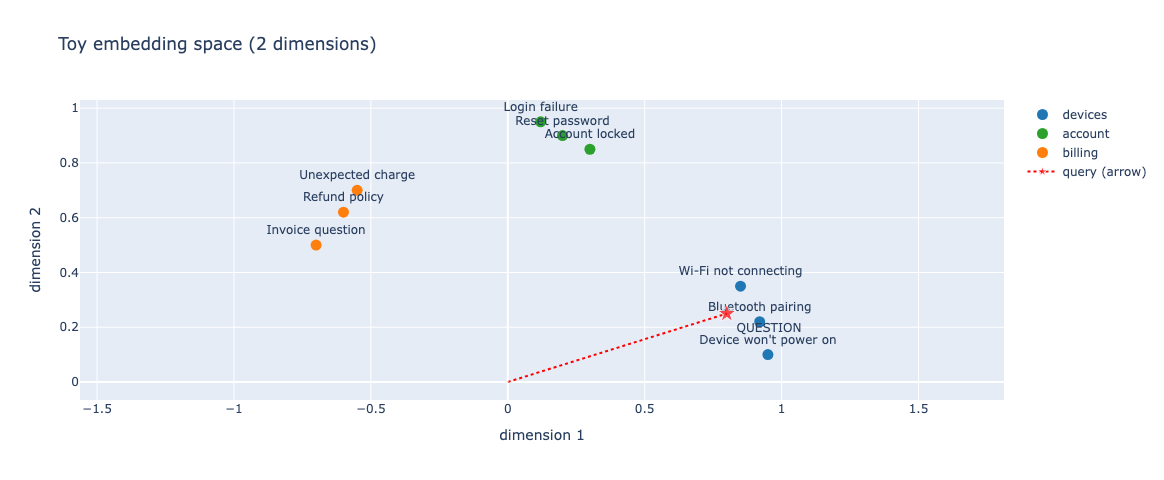

In [4]:
import numpy as np
import plotly.graph_objects as go

def cosine(a, b):
    """Cosine similarity: 1 = same direction, 0 = unrelated, -1 = opposite."""
    a, b = np.array(a, dtype=float), np.array(b, dtype=float)
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

# (title, topic, 2-D toy vector). In a real system the vector would come from an embedding model.
toy_items = [
    ("Bluetooth pairing",     "devices",  (0.92, 0.22)),
    ("Wi-Fi not connecting",  "devices",  (0.85, 0.35)),
    ("Device won't power on", "devices",  (0.95, 0.10)),
    ("Reset password",        "account",  (0.20, 0.90)),
    ("Account locked",        "account",  (0.30, 0.85)),
    ("Login failure",         "account",  (0.12, 0.95)),
    ("Refund policy",         "billing",  (-0.60, 0.62)),
    ("Invoice question",      "billing",  (-0.70, 0.50)),
    ("Unexpected charge",     "billing",  (-0.55, 0.70)),
]
toy = {title: np.array(vec) for title, topic, vec in toy_items}
query = np.array([0.80, 0.25])    # the user's question: "My headphones won't connect"  (try moving it later!)

colors = {"devices": "#1f77b4", "account": "#2ca02c", "billing": "#ff7f0e"}
fig = go.Figure()
for topic, color in colors.items():
    pts = [(t, v) for t, tp, v in toy_items if tp == topic]
    fig.add_trace(go.Scatter(x=[v[0] for _, v in pts], y=[v[1] for _, v in pts], mode="markers+text",
                             text=[t for t, _ in pts], textposition="top center", name=topic,
                             marker=dict(size=11, color=color)))
fig.add_trace(go.Scatter(x=[0, query[0]], y=[0, query[1]], mode="lines+markers+text", name="query (arrow)",
                         text=["", "QUESTION"], textposition="bottom right",
                         line=dict(color="red", dash="dot"), marker=dict(size=[1, 14], symbol="star", color="red")))
fig.update_layout(title="Toy embedding space (2 dimensions)", xaxis_title="dimension 1", yaxis_title="dimension 2",
                  height=480, yaxis=dict(scaleanchor="x", scaleratio=1))
fig.show()

**What you should see:** three clusters. The red star (the question *"My headphones won't connect"*) lands inside the **devices** cluster, far from billing. That is the whole idea of semantic search: **close = similar meaning**.

## 0.2 Measuring "close": distance and similarity
To find the nearest points we need a number for "how close". The common choices:

| Measure | Idea | pgvector operator |
|---|---|---|
| **Euclidean (L2) distance** | straight-line distance between two points | `<->` |
| **Cosine distance** | the **angle** between two arrows, ignoring their length | `<=>` |
| **Negative inner product** | dot product (sign flipped so smaller = closer) | `<#>` |

For text embeddings we use **cosine**: what matters is the *direction* of the arrow (the topic), not how long it is. `cosine similarity = 1 - cosine distance`, so `1.0` = same direction. We will use this exact `1 - (embedding <=> question)` expression in Step 6.

Notice that scaling a vector changes its Euclidean distance, but not its direction:

In [5]:
print("cosine(query, 5 x query)   :", round(cosine(query, 5 * query), 3), "  <- same direction, any length")
print("euclidean distance to it   :", round(float(np.linalg.norm(query - 5 * query)), 3), "  <- looks far away")

cosine(query, 5 x query)   : 1.0   <- same direction, any length
euclidean distance to it   : 3.353   <- looks far away


### TODO 0 · Find the nearest vectors yourself (brute force)
A vector database answers one question: **"which stored vectors are closest to this query vector?"** The simplest way is **brute force**: score the query against *every* stored vector, sort, keep the top **k**.

Replace the `0.0` so each toy vector is scored with `cosine(query, vec)`.

In [6]:
# TODO 0: score every toy vector against the query with cosine(query, vec)
scores = {title: cosine(query, vec) for title, vec in toy.items()}

ranking = sorted(scores.items(), key=lambda pair: pair[1], reverse=True)
print(f"Top 3 for the question (query = {query.tolist()}):")
for title, score in ranking[:3]:
    print(f"  {score:.3f}  {title}")

Top 3 for the question (query = [0.8, 0.25]):
  0.998  Bluetooth pairing
  0.996  Wi-Fi not connecting
  0.980  Device won't power on


**What you should see:** the three **devices** articles on top, "Bluetooth pairing" first. Without your fix every score is `0.0`.

💡 **Try it:** change `query` to `np.array([-0.6, 0.55])` (a billing-like question) or `np.array([0.2, 0.9])` (an account-like question), re-run the plot cell and this cell, and watch the top 3 change.

## 0.3 What is a vector database?
A **vector database** stores vectors so they can be **searched by similarity**. A normal SQL query finds *exact* matches (`WHERE title LIKE '%password%'`); a vector search finds items with similar **meaning**, even with different words ("I can't log in" ≈ "Reset password").

Each row holds three things:
1. the **vector** (the embedding, used for searching),
2. the **original data** (the text, image... that we give back to the user / LLM): the *payload*,
3. **metadata** (id, title, category...) to identify and filter rows.

![A vector database stores the original unstructured data together with its embeddings](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-166.png)

Searching works in two moves: the query is encoded with the same model, then the database returns the **nearest** stored vectors together with their original data.

![The query "Venice" is encoded and the database finds its nearest neighbours in the embedding space](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-162.png)

Here is a vector database in about 15 lines. Read it, then run it: it is the same idea as the Supabase tables you will use later (`article_id`, `title`, `category`, `content` + `embedding`).

In [7]:
class ToyVectorDB:
    """A vector database in a few lines: store (id, vector, payload) and search by similarity."""
    def __init__(self):
        self.rows = []                                   # each row = id + vector + payload (original data / metadata)

    def add(self, row_id, vector, payload):
        self.rows.append({"id": row_id, "vector": np.array(vector, dtype=float), "payload": payload})

    def search(self, query_vector, k=3):
        scored = [(cosine(query_vector, row["vector"]), row) for row in self.rows]   # brute force: compare with EVERY row
        scored.sort(key=lambda pair: pair[0], reverse=True)
        return [(round(score, 3), row["id"], row["payload"]) for score, row in scored[:k]]

toy_db = ToyVectorDB()
for number, (title, topic, vec) in enumerate(toy_items, start=1):
    toy_db.add(f"T-{number:02d}", vec, {"title": title, "category": topic})

for score, row_id, payload in toy_db.search(query, k=3):
    print(score, row_id, payload)

0.998 T-01 {'title': 'Bluetooth pairing', 'category': 'devices'}
0.996 T-02 {'title': 'Wi-Fi not connecting', 'category': 'devices'}
0.98 T-03 {'title': "Device won't power on", 'category': 'devices'}


**What you should see:** the same top 3 as before, but now each hit comes back with its **id and payload**, not just a score. The vector is only the *key* used to find the row.

## 0.4 Why real vector databases are more than a `for` loop
Our `search()` compares the query with **every** row (this is exact *k-nearest-neighbour* search). That is fine for 9 rows, or the 19 articles in this lab, but a production database may hold **millions** of vectors. With 10 million vectors of 1,536 numbers, one question would need about **15 billion multiplications**.

![Brute force: the query vector is matched against all the stored vectors](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image.png)

Real vector databases build an **index** and use **approximate nearest neighbour (ANN)** search: they only look inside a promising neighbourhood of the space instead of at every vector. It is a trade-off: a tiny loss of accuracy for a huge gain in speed. Common index types are HNSW and IVF; pgvector (Postgres) supports both.

![kNN searches every vector, ANN searches only a narrowed part of the space](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-187.png)

### Part 0 checkpoint
1. What does the *position* of a point in the embedding space mean?
2. Why do we compare vectors with the **angle** (cosine) rather than raw length?
3. What three things does one row of a vector database contain?
4. What does ANN give up, and what does it gain?

Now we use these ideas on real text: **Phase A** builds the knowledge base, **Phase B** answers questions.

---
# Phase A · Indexing: prepare the knowledge
## Step 1 · Create chunks
The first step is to break the extra knowledge into **chunks** *before* embedding and storing it.

![A knowledge base of DOC and PDF files is chunked into smaller pieces](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-6.png)

**Why we chunk**
- Documents can be large, but an embedding model accepts only limited input (`text-embedding-3-small` takes up to 8,191 tokens). Text has to fit.
- If we did **not** chunk, a whole document would get a **single embedding**: one vector that averages every topic in it. A search for one specific detail would match that blurry average poorly, and we would hand the LLM a whole document when it only needs one paragraph.
- Small, focused chunks give **sharper embeddings** and let us retrieve exactly the relevant passage.

![One large document is split into several smaller chunks](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-7.png)

**How big should a chunk be?** It is a trade-off: too small loses context, too large blurs the topic. In this lab we use one simple strategy: pack whole sentences up to a size limit. **Overlap** repeats a little text between neighbouring chunks so an idea cut at a boundary is still intact somewhere.

First, look at the instructor's articles. They are very short (one or two sentences each), so **one article = one chunk** in this lab.

In [9]:
display(fetch_df("SELECT article_id, title, category, content, LENGTH(content) AS chars FROM shared.knowledge_articles ORDER BY chars DESC LIMIT 5"))

,article_id,title,category,content,chars
0,KB-003,Device cannot connect to Wi-Fi,Technical issue,"Check Wi-Fi credentials, network availability ...",168
1,KB-004,Product will not power on,Technical issue,"Confirm power supply, cable, battery charge an...",160
2,KB-005,Software installation fails,Technical issue,"Verify supported operating system, available d...",151
3,KB-002,Login failure after repeated attempts,Technical issue,Repeated failed sign-ins may temporarily lock ...,149
4,KB-013,Cancellation before renewal,Cancellation request,Check plan terms and the upcoming renewal date...,149


**What you should see:** every article is only about 110-170 characters, far below the embedding model's limit, so no splitting is needed. Real knowledge bases are not that tidy (manuals, PDFs, long web pages), so let's see chunking on a longer text. The function below packs whole sentences into chunks of at most `max_chars` characters, with one sentence of overlap.

In [10]:
import re

def chunk_text(text, max_chars=300, overlap_sentences=1):
    """Pack whole sentences into chunks of at most `max_chars` characters.
    The last `overlap_sentences` sentences of a chunk are repeated at the start of the next one,
    so an idea that straddles a boundary is still fully visible in at least one chunk."""
    sentences = re.split(r"(?<=[.!?])\s+", text.strip())
    chunks, current = [], []
    for sentence in sentences:
        if current and len(" ".join(current + [sentence])) > max_chars:
            chunks.append(" ".join(current))
            current = current[-overlap_sentences:] if overlap_sentences else []
        current.append(sentence)
    if current:
        chunks.append(" ".join(current))
    return chunks

long_guide = (
    "Bluetooth pairing guide. Make sure Bluetooth is switched on for both devices and that they are within one metre of each other. "
    "If the device does not appear in the list, put it into pairing mode: for most headphones this means holding the power button for five seconds until the light flashes. "
    "Remove stale pairings. Open Bluetooth settings on your phone, tap the old entry for the device and choose Forget. Then start a fresh scan. "
    "Check compatibility. Older devices that only support Bluetooth 2.1 may not pair with phones that require Bluetooth 5 security. "
    "Billing guide. Invoices are issued on the first day of each month. Payment is due within 14 days. "
    "Late payments may pause the account until the balance is cleared. Contact billing support if you see an unfamiliar charge."
)

chunks = chunk_text(long_guide, max_chars=300, overlap_sentences=1)
print(f"{len(long_guide)} characters  ->  {len(chunks)} chunks\n")
for i, chunk in enumerate(chunks, 1):
    print(f"--- chunk {i} ({len(chunk)} chars) ---\n{chunk}\n")


780 characters  ->  4 chunks

--- chunk 1 (293 chars) ---
Bluetooth pairing guide. Make sure Bluetooth is switched on for both devices and that they are within one metre of each other. If the device does not appear in the list, put it into pairing mode: for most headphones this means holding the power button for five seconds until the light flashes.

--- chunk 2 (280 chars) ---
If the device does not appear in the list, put it into pairing mode: for most headphones this means holding the power button for five seconds until the light flashes. Remove stale pairings. Open Bluetooth settings on your phone, tap the old entry for the device and choose Forget.

--- chunk 3 (257 chars) ---
Open Bluetooth settings on your phone, tap the old entry for the device and choose Forget. Then start a fresh scan. Check compatibility. Older devices that only support Bluetooth 2.1 may not pair with phones that require Bluetooth 5 security. Billing guide.

--- chunk 4 (220 chars) ---
Billing guide. Invoice

**What you should see:** the 780-character guide becomes 4 chunks. Check these behaviours:
- Chunks never cut a sentence in half.
- Each chunk starts with the last sentence of the previous one (the **overlap**).
- Chunk 3 ends with the first words of the billing section: **chunk boundaries are imperfect**, so real systems tune chunk size and overlap.

💡 **Try it:** change `max_chars` to `150` or `600`, or set `overlap_sentences=0`, and re-run the cell. Notice how many chunks you get and whether topics get mixed.

## Step 2 · Generate embeddings
After chunking, each chunk is turned into an **embedding**: a list of numbers (a *vector*) that captures the **meaning** of the text. With `text-embedding-3-small` every text becomes a vector of **1,536 numbers**.

![Each chunk goes through the embedding model and becomes a vector](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-9.png)

**Why this works:** texts with similar meaning get vectors that point in similar directions, even when they share no words ("headphones won't pair" ≈ "connect wireless earbuds"). That lets us search by **meaning** instead of exact keywords.

These are *context* embedding models (they read the whole sentence), not word-by-word embedding models. Most are **bi-encoders**: query and document are each encoded **independently** into the same vector space. That means document vectors can be computed **once, ahead of time**, and stored. Compare this with a *cross-encoder* (see Step 7), which reads query and document together: more accurate, but too slow to run over the whole knowledge base.

Let's see this with your own eyes. Two sentences about connecting a device, and one about refunds. **Cosine similarity** is close to 1 for similar direction and lower for unrelated meaning.

In [11]:
demo_texts = [
    "My Bluetooth headphones will not pair with my phone.",
    "How do I connect wireless earbuds to a new phone?",
    "What is the refund policy for damaged packages?",
]
demo_vectors = [embed(t) for t in demo_texts]

print("Numbers per embedding:", len(demo_vectors[0]))
print("First 5 numbers of text 1:", [round(x, 4) for x in demo_vectors[0][:5]])
print()
print("headphones  vs  earbuds :", round(cosine(demo_vectors[0], demo_vectors[1]), 3), " <- same topic, different words")
print("headphones  vs  refunds :", round(cosine(demo_vectors[0], demo_vectors[2]), 3), " <- different topic")

RateLimitError: Error code: 429 - {'error': {'message': 'Your organization has reached its configured enforced spend limit. Update your limit at https://platform.openai.com/settings/organization/limits.', 'type': 'insufficient_quota', 'param': None, 'code': 'organization_spend_limit_exceeded'}}

**What you should see:** 1,536 numbers per text, and a clearly **higher** similarity for the two connection questions than for the refund one. Meaning, not wording, drives the score.

### TODO 1 · Create your own embedding
Now embed a real article: the new article you will add to the knowledge base. It is short, so it is a single chunk. **Embed the title and the content together**, because the title carries useful meaning.

In [ ]:
new_id=f"TEAM-{TEAM_NUMBER:02d}-001"
article_title="Troubleshooting Bluetooth pairing"
article_content="Check Bluetooth is enabled on both devices, remove stale pairings, restart pairing mode, and verify device compatibility. Escalate if repeated attempts fail."
# TODO 1: Call embed with title + content, not an empty string
new_embedding = embed(article_title + "\n" + article_content)
print("Embedding dimensions:", len(new_embedding))
assert len(new_embedding)==1536

## Step 3 · Store embeddings in a vector database
The embeddings are now saved in a **vector database**. Think of it as the **memory of your RAG app**: this is exactly where all the extra knowledge lives, and the user's question will be answered from it.

![Chunk embeddings are stored in the vector database, each point in embedding space is one chunk](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-10.png)

💡 A vector database stores **three things per row**: the **vector** (used for searching), the **original text** (what we give the LLM later) and **metadata** (id, title, category...). We search with vectors but we answer with the original text.

Here the vector database is **PostgreSQL with the pgvector extension** (`vector(1536)` column), so your knowledge sits next to ordinary SQL tables. The cell below is provided: it inserts your article into your **team schema** (`ON CONFLICT ... DO UPDATE` means re-running it just overwrites your row instead of failing).

In [ ]:
with closing(connect()) as conn:
    with conn.transaction():
        with conn.cursor() as cur:
            cur.execute(f"""INSERT INTO {TEAM_SCHEMA}.knowledge_articles
                (article_id,title,content,embedding) VALUES (%s,%s,%s,%s::extensions.vector)
                ON CONFLICT (article_id) DO UPDATE SET title=EXCLUDED.title,
                content=EXCLUDED.content,embedding=EXCLUDED.embedding""",
                (new_id,article_title,article_content,vector_literal(new_embedding)))
print("Saved:",new_id)

**Check:** confirm your row exists and has an embedding. The instructor's 18 articles live in `shared.knowledge_articles`; yours lives in your team table. Search in Step 6 will look at **both**. More knowledge can be added at any time by repeating Steps 1-3.

In [ ]:
display(fetch_df(f"SELECT article_id, title, LEFT(content, 60) AS preview, embedding IS NOT NULL AS has_embedding FROM {TEAM_SCHEMA}.knowledge_articles ORDER BY article_id"))

---
# Phase B · Query: answer a user question
The knowledge base is ready. From here on, everything happens **each time a user asks something**.

## Step 4 · User input query
The user types a question: just a string describing the information they want. This is the question we will answer.

![The user types a question into the application](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-11.png)

## Step 5 · Embed the query
The question is converted into a vector with **the same embedding model** used for the chunks in Step 2 (`EMBED_MODEL`).

![The user query goes through the same embedding model and becomes a query embedding](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-12.png)

**Why the same model?** Every model has its own "map of meaning". Vectors from different models (or different dimensions) live in different spaces and cannot be compared. The same model puts the question and the articles on the same map, so "nearby" really means "similar in meaning".

In [ ]:
question = "How do I fix Bluetooth pairing problems?"
question_embedding = vector_literal(embed(question))   # Step 5: same embed() and same model as Step 2
print("Question:", question)
print("Question vector has", question_embedding.count(",") + 1, "numbers, first characters:", question_embedding[:60], "...")

**What you should see:** the question is now 1,536 numbers, formatted as a text literal (`[0.01,-0.02,...]`) that PostgreSQL can cast with `::extensions.vector`.

## Step 6 · Retrieve similar chunks
The vector database compares the question vector against the stored vectors and returns the **k** most similar chunks (here `k = 3`, set by `LIMIT 3`). These are expected to contain information related to the question, giving the LLM material to answer from.

![The query embedding is compared with the vectors in the vector database](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-13.png)

**How the comparison works in SQL**
- `<=>` is pgvector's **cosine distance**: `0` = same direction, larger = less similar.
- `1 - distance` gives a **similarity** score that is easier to read: closer to `1` = more similar.
- `ORDER BY embedding <=> question LIMIT 3` = "give me the 3 closest rows".
- We search the instructor's `shared` articles **and** your team's articles together with `UNION ALL`.

At large scale vector databases speed this up with **approximate nearest neighbour (ANN)** indexes (e.g. HNSW): slightly less exact, far faster. Our tables are tiny, so Postgres simply compares the question with every row.

![Vector database lookup: the query vector (orange) finds its nearest vectors (blue) and returns similar chunks](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-14.png)

### TODO 2 · Similarity search in PostgreSQL
Replace both `TODO_OPERATOR` placeholders with the cosine-distance operator `<=>`.

In [ ]:
# TODO 2: Fill in the cosine-distance operator: <=>
query=f"""SELECT article_id,title,content,
               1 - (embedding <=> %s::extensions.vector) AS similarity
          FROM (SELECT article_id,title,content,embedding FROM shared.knowledge_articles
                UNION ALL
                SELECT article_id,title,content,embedding FROM {TEAM_SCHEMA}.knowledge_articles) kb
          ORDER BY embedding <=> %s::extensions.vector LIMIT 3"""
passages=fetch_df(query,(question_embedding,question_embedding))
display(passages[["article_id","title","similarity"]])

**What you should see:** 3 rows sorted by `similarity` (highest first). Your own `TEAM-xx-001` Bluetooth article should be at or near the top. If it is not there, check that Step 3 ran and that you embedded title **and** content in TODO 1.

## Step 7 · Re-rank the chunks *(optional, not run in this lab)*
Retrieval is fast but rough: a bi-encoder compares two **pre-computed** vectors, so it never sees the question and the chunk together. Some applications therefore add a **re-ranking** step: a more sophisticated model, often a **cross-encoder**, reads the question *together with* each retrieved chunk and gives it a relevance score. The chunks are re-ordered so the most relevant come first.

![A cross-encoder scores each retrieved chunk together with the user query](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-15.png)

Typical pattern: retrieve generously (e.g. top 20 with the fast vector search), re-rank, then keep the best few (e.g. top 3) for the LLM. Trade-off: better precision for extra latency and cost.

That said, **not every RAG app uses it**. Many simply rely on the similarity scores from Step 6, and so do we here. Keep it in mind as the first upgrade when retrieval quality is not good enough.

## Step 8 · Generate the final response
Almost done! The top chunks are given to the LLM. A **prompt template** combines the user's original question with the retrieved chunks, and the LLM writes an answer that is based on that context.

![A prompt template combines the query and the retrieved chunks, the LLM streams the answer to the user](https://raw.githubusercontent.com/Ngxba/fpt-ghc-data-ai-workshop-level1/main/assets/image-16.png)

Two messages are sent:
- **System prompt = the rules**: answer *only* from the provided articles, cite article IDs, and say "I do not know" when the context does not answer. This is what makes the answer **grounded** and keeps the model from inventing policies.
- **User prompt = the question + the retrieved context** (each article labelled with its `[article_id]` so the model can cite it).

The LLM never searches the database itself. It only sees the text you paste into the prompt. That is why retrieval quality (Steps 1-6) decides answer quality.

### TODO 3 · Build a grounded prompt; generate an OpenAI answer
Put the retrieved `context` into the user prompt in place of the `TODO` placeholder.

In [ ]:
context="\n\n".join(f"[{r.article_id}] {r.title}: {r.content}" for r in passages.itertuples())
# TODO 3: Provide the retrieved context; ask the LLM to cite article IDs.
system_prompt = "Answer ONLY from knowledge articles. Cite article IDs. If unsure, say I do not know."
user_prompt = f"Question: {question}\n\nKnowledge articles:\n{context}"
response=client.responses.create(model=CHAT_MODEL,input=[
    {"role":"system","content":system_prompt},
    {"role":"user","content":user_prompt}
])
print(response.output_text)

**What you should see:** a short answer built from your Bluetooth article that **cites the article ID(s)** in the text. Print `user_prompt` if you want to see exactly what the LLM received.

## Putting Steps 4-8 together
The cell below wraps the query phase into two reusable functions so you can ask any question:
- `retrieve_articles(question, k)` = Steps 4-6 (embed the question, search, return the top-k).
- `grounded_answer(question, passages)` = Step 8 (build the prompt and call the LLM).

Step 7 (re-ranking) would sit between them.

In [ ]:
def retrieve_articles(question, k=3):
    q_vec = vector_literal(embed(question))
    # Instructor-provisioned views/tables; schema is constructed only from a numeric team ID.
    query = f"""
      SELECT article_id, title, content, 1 - (embedding <=> %s::extensions.vector) AS similarity
      FROM (
         SELECT article_id, title, content, embedding FROM shared.knowledge_articles
         UNION ALL
         SELECT article_id, title, content, embedding FROM {TEAM_SCHEMA}.knowledge_articles
      ) kb
      WHERE embedding IS NOT NULL
      ORDER BY embedding <=> %s::extensions.vector
      LIMIT %s
    """
    return fetch_df(query, (q_vec,q_vec,int(k)))

def grounded_answer(question, passages):
    context = "\n\n".join(
        f"[{row.article_id}] {row.title}: {row.content}" for row in passages.itertuples()
    )
    response = client.responses.create(
        model=CHAT_MODEL,
        input=[
          {"role":"system","content": "Answer only from retrieved knowledge articles. Cite the article IDs in square brackets. If context does not answer the question, say you do not know. Do not invent policies."},
          {"role":"user","content":f"Question: {question}\n\nRetrieved articles:\n{context}"},
        ],
    )
    return response.output_text

## Test an unsupported question
RAG answers are only as good as the knowledge that was retrieved. Ask something the knowledge base does **not** cover. The system prompt tells the model to say "I do not know" instead of guessing.

In [ ]:
# Try another question, and discuss why RAG cannot guarantee every answer is factual.
question2="What is the guaranteed refund amount for a damaged device?"
passages2=retrieve_articles(question2,3)
print(grounded_answer(question2,passages2))

### RAG checkpoint
1. Verify your team article is retrieved for the Bluetooth question.
2. Inspect whether source citations actually match article IDs.
3. Explain why the LLM should refuse to invent refund policies.
4. Contrast `SQL COUNT(*)` with semantic search: one computes facts from rows; the other finds relevant prose.
5. Explain why a long document is split into chunks before embedding (Step 1) and what overlap is for.
6. Explain why the question must be embedded with the **same** model as the articles (Step 5).
7. Which steps run once (indexing) and which run for every question (query)? Where would a re-ranker go?